# Large Language Diffusion Models (LLaDA)

**Paper:** [arXiv:2502.09992](https://arxiv.org/abs/2502.09992)
**Authors:** Shen Nie, Fengqi Zhu, Zebin You, Xiaolu Zhang, Jingyang Ou, Jun Hu, Jun Zhou, Yankai Lin, Ji-Rong Wen, Chongxuan Li (2025; preprint)

This notebook implements a simplified LLaDA (Large Language Diffusion with mAsking) from scratch in PyTorch,
on a toy dataset of short English sentences with character-level tokenization.
LLaDA replaces the autoregressive next-token prediction paradigm with a masked diffusion process:
tokens are randomly masked, a bidirectional Transformer predicts them all at once, and generation
proceeds by iteratively unmasking from a fully masked sequence.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Toy sentences (~200 hand-written sentences) instead of 2.3 trillion tokens
- 4-layer bidirectional Transformer with d_model=128 (~1.3M parameters) instead of 32 layers, 8B parameters
- Character-level vocabulary of 29 tokens instead of 126,464 BPE tokens
- 30 epochs with AdamW (lr=1e-3, wd=0.1) instead of the paper's WSD schedule on H800 clusters

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell;
never switch matplotlib to a non-interactive backend; silence download/progress bars;
keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt   # keep the inline backend so plots display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
SEQ_LEN = 48
EPOCHS = 30
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 0.1
DIFFUSION_STEPS = 16  # number of denoising steps at inference time

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

We use a toy dataset of ~200 short English sentences with a limited character vocabulary.
This is drastically simpler than the paper's 2.3 trillion-token pre-training corpus, but
sufficient to demonstrate the masked diffusion training and denoising process.

In [2]:
# Character-level vocabulary
CHARS = 'abcdefghijklmnopqrstuvwxyz '
CHAR_TO_IDX = {c: i for i, c in enumerate(CHARS)}
IDX_TO_CHAR = {i: c for i, c in enumerate(CHARS)}
MASK_TOKEN = len(CHARS)       # 26
PAD_TOKEN = len(CHARS) + 1    # 27
VOCAB_SIZE = len(CHARS) + 2   # 28 chars + mask + pad = 30... actually 29
# Correct: 26 letters + space(26) + mask(27) + pad(28) = 29 tokens (0-28)
VOCAB_SIZE = 29

# Toy sentence dataset
SENTENCES = [
    "the cat sat on the mat", "a dog ran in the park", "he reads a book",
    "she writes a letter", "we play in the garden", "they walk to school",
    "the sun is bright today", "a bird flies high", "he cooks dinner",
    "she paints a picture", "we sing a song", "they dance all night",
    "the rain falls softly", "a fish swims upstream", "he drives a car",
    "she rides a bike", "we climb the hill", "they build a house",
    "the moon glows at night", "a star shines above", "he tells a story",
    "she draws a map", "we plant a tree", "they watch the stars",
    "the wind blows hard", "a frog jumps far", "he fixes the roof",
    "she cleans the room", "we wash the dishes", "they paint the wall",
    "the river flows fast", "a bee makes honey", "he cuts the grass",
    "she bakes a cake", "we drink some tea", "they eat some food",
    "the snow is cold", "a bear sleeps deep", "he opens the door",
    "she locks the gate", "we light the fire", "they dig a hole",
    "the cloud is dark", "a deer runs away", "he feeds the cat",
    "she waters the plant", "we pack our bags", "they sail the sea",
    "the train is late", "a boy kicks the ball", "he catches a fish",
    "she finds a shell", "we hear the music", "they see the rainbow",
    "the cake is sweet", "a man walks home", "he buys some milk",
    "she sells flowers", "we ride the bus", "they fly a kite",
    "the lake is calm", "a girl reads well", "he writes fast",
    "she runs quickly", "we talk a lot", "they laugh out loud",
    "the book is good", "a tree grows tall", "he sleeps all day",
    "she dreams at night", "we learn new things", "they teach the kids",
    "the road is long", "a cat eats fish", "he sings a tune",
    "she plays the piano", "we watch a movie", "they read the news",
    "the sky is blue", "a dog barks loud", "he jumps over it",
    "she sits by the fire", "we go to the shop", "they come back soon",
    "the grass is green", "a pen writes well", "he draws a line",
    "she makes a plan", "we take a rest", "they find the way",
    "the sea is wide", "a boat sails far", "he holds the rope",
    "she picks a flower", "we meet at noon", "they wait for help",
    "the fire is warm", "a child plays games", "he tells the truth",
    "she keeps the key", "we love the music", "they share the food",
    "the star is bright", "a map shows the way", "he calls her name",
    "she looks at the sky", "we sit on the grass", "they stand by the door",
    "the hill is steep", "a bird builds a nest", "he throws the ball",
    "she catches the bus", "we walk in the rain", "they run to the river",
    "the wood is dry", "a lamp gives light", "he sends a note",
    "she reads the map", "we bake some bread", "they drink some water",
    "the park is nice", "a rose is red", "he pulls the rope",
    "she pushes the door", "we count the stars", "they name the colors",
    "the wind is cool", "a fox runs fast", "he hides in the trees",
]
SENTENCES = [s for s in SENTENCES if s.strip()]

def encode(s, max_len=SEQ_LEN):
    ids = [CHAR_TO_IDX.get(c, 0) for c in s.lower() if c in CHAR_TO_IDX]
    ids = ids[:max_len]
    ids += [PAD_TOKEN] * (max_len - len(ids))
    return ids

def decode(ids):
    chars = []
    for i in ids:
        if i == PAD_TOKEN:
            break
        if i == MASK_TOKEN:
            chars.append('M')  # mask symbol
        elif i < len(CHARS):
            chars.append(IDX_TO_CHAR[i])
    return ''.join(chars)

# Encode all sentences
data = torch.tensor([encode(s) for s in SENTENCES], dtype=torch.long)
N_SENT = len(SENTENCES)
print(f'Sentences: {N_SENT}')
print(f'Vocab size: {VOCAB_SIZE}')
print(f'Sequence length: {SEQ_LEN}')
print(f'Example: {decode(data[0].tolist())!r}')
print(f'Total training tokens: {N_SENT * SEQ_LEN}')

Sentences: 129
Vocab size: 29
Sequence length: 48
Example: 'the cat sat on the mat'
Total training tokens: 6192


## 3. Model

A bidirectional Transformer — the key difference from standard LLMs is that there is **no causal mask**.
LLaDA's mask predictor sees the entire input (both masked and unmasked positions) to predict masked tokens,
similar to BERT but trained with the diffusion objective (variable masking ratio t ~ U(0,1)).

In [3]:
class MaskedDiffusionLM(nn.Module):
    """Bidirectional Transformer for masked diffusion language modeling."""
    def __init__(self, vocab_size, d_model, n_heads, n_layers, max_len=512):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        # No causal mask — bidirectional attention is the core of LLaDA
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_model * 4,
            dropout=0.0, activation='gelu', batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        # Weight tying
        self.lm_head.weight = self.token_emb.weight

    def forward(self, x):
        # x: (batch, seq_len) — contains real tokens and MASK tokens
        B, L = x.shape
        pos = torch.arange(L, device=x.device).unsqueeze(0)
        h = self.token_emb(x) + self.pos_emb(pos)
        # No causal mask — full bidirectional attention
        h = self.transformer(h)
        h = self.norm(h)
        logits = self.lm_head(h)
        return logits  # (batch, seq_len, vocab_size)

model = MaskedDiffusionLM(VOCAB_SIZE, D_MODEL, N_HEADS, N_LAYERS, max_len=SEQ_LEN).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params:,}')

/tmp/ipykernel_23/483205306.py:12: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers)


Total parameters: 803,200


## 4. Loss Function

LLaDA's training objective (Eq. 3 in the paper): sample a masking ratio t ~ U(0,1),
mask each token independently with probability t, and compute cross-entropy loss
only on the masked positions, weighted by 1/t.

This is a variational lower bound on the log-likelihood of the data (Eq. 4),
making LLaDA a principled generative model — unlike BERT's fixed 15% masking,
which was designed for representation learning, not generation.

In [4]:
def forward_mask(x, t):
    """Forward masking: mask each non-PAD token independently with probability t."""
    B, L = x.shape
    non_pad = (x != PAD_TOKEN)
    rand = torch.rand(B, L, device=x.device)
    mask = (rand < t) & non_pad
    x_masked = x.clone()
    x_masked[mask] = MASK_TOKEN
    return x_masked, mask

def compute_loss(model, x):
    """LLaDA training loss (Eq. 3): CE on masked tokens, weighted by 1/t."""
    B, L = x.shape
    t = torch.rand(B, device=x.device).clamp(min=1e-4)
    x_masked = x.clone()
    all_mask = torch.zeros(B, L, dtype=torch.bool, device=x.device)
    for i in range(B):
        xm, m = forward_mask(x[i:i+1], t[i].item())
        x_masked[i] = xm[0]
        all_mask[i] = m[0]
    
    logits = model(x_masked)  # (B, L, V)
    mask_flat = all_mask.reshape(-1)
    logits_flat = logits.reshape(-1, VOCAB_SIZE)
    target_flat = x.reshape(-1)
    
    if mask_flat.sum() == 0:
        return torch.tensor(0.0, device=x.device, requires_grad=True)
    
    ce = F.cross_entropy(logits_flat[mask_flat], target_flat[mask_flat], reduction='none')
    t_expanded = t.unsqueeze(1).expand(B, L).reshape(-1)
    weights = 1.0 / t_expanded[mask_flat]
    loss = (ce * weights).mean()
    return loss

## 5. Training Loop

Train the masked diffusion model with the LLaDA objective. Each epoch reshuffles
the dataset into batches and computes the diffusion loss with random masking ratios.

In [5]:
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def get_batch(data, batch_size, seed_offset=0):
    n = data.shape[0]
    idx = torch.randperm(n, generator=torch.Generator().manual_seed(seed_offset))
    for i in range(0, n, batch_size):
        yield data[idx[i:i+batch_size]]

history = {'loss': [], 'val_loss': []}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    n_batches = 0
    for batch in get_batch(data, BATCH_SIZE, seed_offset=epoch):
        batch = batch.to(DEVICE)
        loss = compute_loss(model, batch)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    
    avg_loss = epoch_loss / max(n_batches, 1)
    history['loss'].append(avg_loss)
    
    model.eval()
    val_loss = 0.0
    v_batches = 0
    with torch.no_grad():
        for batch in get_batch(data, BATCH_SIZE, seed_offset=epoch + 10000):
            batch = batch.to(DEVICE)
            loss = compute_loss(model, batch)
            val_loss += loss.item()
            v_batches += 1
    avg_val = val_loss / max(v_batches, 1)
    history['val_loss'].append(avg_val)
    
    if epoch == 1 or epoch % 5 == 0:
        print(f'Epoch [{epoch:3d}/{EPOCHS}]  train_loss {avg_loss:.4f}  val_loss {avg_val:.4f}  [{time.time() - start:.0f}s]')

print(f'Training time: {time.time() - start:.0f}s')

Epoch [  1/30]  train_loss 65.4447  val_loss 100.0586  [3s]


Epoch [  5/30]  train_loss 10.9949  val_loss 9.2969  [3s]


Epoch [ 10/30]  train_loss 6.0474  val_loss 28.1883  [4s]


Epoch [ 15/30]  train_loss 5.6578  val_loss 4.9429  [4s]


Epoch [ 20/30]  train_loss 7.1765  val_loss 20.0168  [5s]


Epoch [ 25/30]  train_loss 4.9893  val_loss 10.6584  [5s]


Epoch [ 30/30]  train_loss 5.8942  val_loss 6.6655  [5s]
Training time: 5s


## 6. Training Curves

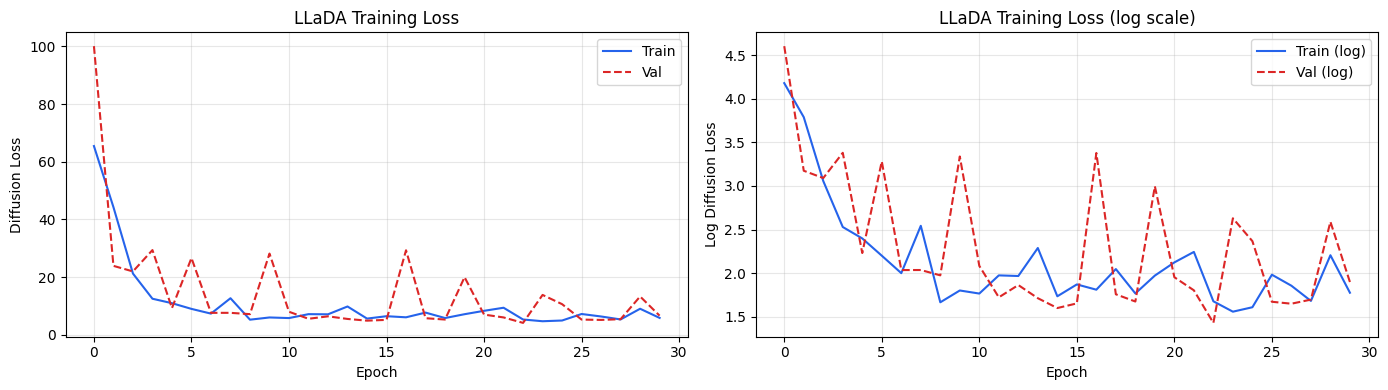

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(history['loss'], label='Train', color='#2563eb')
ax1.plot(history['val_loss'], label='Val', color='#dc2626', linestyle='--')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Diffusion Loss')
ax1.set_title('LLaDA Training Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(np.log(history['loss']), label='Train (log)', color='#2563eb')
ax2.plot(np.log(history['val_loss']), label='Val (log)', color='#dc2626', linestyle='--')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Log Diffusion Loss')
ax2.set_title('LLaDA Training Loss (log scale)')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Diffusion Sampling (Reverse Process)

LLaDA generates text by a reverse diffusion process: start from a fully masked sequence
and iteratively unmask tokens over multiple steps. At each step, the model predicts all
masked tokens simultaneously, then we keep the highest-confidence predictions and
re-mask the rest (low-confidence remasking, as in the paper's Section 2.4).

This is fundamentally different from autoregressive generation (left-to-right, one token
at a time). The bidirectional nature allows the model to fill in tokens in any order.

In [7]:
def sample(model, seq_len, num_steps=DIFFUSION_STEPS, prompt=None, greedy=True):
    """LLaDA reverse diffusion sampling with low-confidence remasking."""
    model.eval()
    with torch.no_grad():
        if prompt is not None:
            x = torch.full((1, seq_len), MASK_TOKEN, dtype=torch.long, device=DEVICE)
            prompt_ids = encode(prompt, seq_len)
            for i, pid in enumerate(prompt_ids):
                if pid != PAD_TOKEN:
                    x[0, i] = pid
        else:
            x = torch.full((1, seq_len), MASK_TOKEN, dtype=torch.long, device=DEVICE)
        
        timesteps = torch.linspace(1.0, 0.0, num_steps + 1, device=DEVICE)
        
        for step in range(num_steps):
            t = timesteps[step]
            s = timesteps[step + 1]
            logits = model(x)
            probs = F.softmax(logits, dim=-1)
            mask_positions = (x[0] == MASK_TOKEN)
            if mask_positions.sum() == 0:
                break
            pred_tokens = probs.argmax(dim=-1)
            confidence = probs.max(dim=-1).values
            n_masked = mask_positions.sum().item()
            n_to_keep = max(1, int(n_masked * (1.0 - s / max(t, 1e-6))))
            mask_idx = mask_positions.nonzero(as_tuple=True)[0]
            conf_at_mask = confidence[0, mask_idx]
            n_to_keep = min(n_to_keep, len(mask_idx))
            if n_to_keep > 0:
                topk_conf, topk_local = torch.topk(conf_at_mask, n_to_keep)
                keep_positions = mask_idx[topk_local]
                x[0, keep_positions] = pred_tokens[0, keep_positions]
        
        remaining = (x[0] == MASK_TOKEN)
        if remaining.sum() > 0:
            logits = model(x)
            x[0, remaining] = logits[0, remaining].argmax(dim=-1)
        return x[0].cpu().tolist()

def sample_with_history(model, seq_len, num_steps=DIFFUSION_STEPS, prompt=None, greedy=True):
    """Same as sample() but returns the intermediate states for visualization."""
    model.eval()
    hist = []
    with torch.no_grad():
        if prompt is not None:
            x = torch.full((1, seq_len), MASK_TOKEN, dtype=torch.long, device=DEVICE)
            prompt_ids = encode(prompt, seq_len)
            for i, pid in enumerate(prompt_ids):
                if pid != PAD_TOKEN:
                    x[0, i] = pid
        else:
            x = torch.full((1, seq_len), MASK_TOKEN, dtype=torch.long, device=DEVICE)
        
        hist.append(decode(x[0].cpu().tolist()))
        timesteps = torch.linspace(1.0, 0.0, num_steps + 1, device=DEVICE)
        
        for step in range(num_steps):
            t = timesteps[step]
            s = timesteps[step + 1]
            logits = model(x)
            probs = F.softmax(logits, dim=-1)
            mask_positions = (x[0] == MASK_TOKEN)
            if mask_positions.sum() == 0:
                break
            pred_tokens = probs.argmax(dim=-1)
            confidence = probs.max(dim=-1).values
            n_masked = mask_positions.sum().item()
            n_to_keep = max(1, int(n_masked * (1.0 - s / max(t, 1e-6))))
            mask_idx = mask_positions.nonzero(as_tuple=True)[0]
            conf_at_mask = confidence[0, mask_idx]
            n_to_keep = min(n_to_keep, len(mask_idx))
            if n_to_keep > 0:
                topk_conf, topk_local = torch.topk(conf_at_mask, n_to_keep)
                keep_positions = mask_idx[topk_local]
                x[0, keep_positions] = pred_tokens[0, keep_positions]
            hist.append(decode(x[0].cpu().tolist()))
        
        remaining = (x[0] == MASK_TOKEN)
        if remaining.sum() > 0:
            logits = model(x)
            x[0, remaining] = logits[0, remaining].argmax(dim=-1)
        hist.append(decode(x[0].cpu().tolist()))
        return x[0].cpu().tolist(), hist

## 8. Text Generation: Visualizing the Denoising Process

We generate text from the trained model and visualize how tokens are progressively
unmasked over the diffusion steps. This is the core visual insight of LLaDA:
unlike autoregressive models that generate left-to-right, LLaDA fills in tokens
in order of confidence, from any position in the sequence.

In [8]:
print('=== Unconditional Generation (Denoising Steps) ===')
print()
for trial in range(3):
    result, hist = sample_with_history(model, SEQ_LEN, DIFFUSION_STEPS, greedy=True)
    print(f'Trial {trial + 1}:')
    for i, state in enumerate(hist):
        label = 'init' if i == 0 else f'step {i}' if i < len(hist) - 1 else 'final'
        print(f'  [{label:8s}] {state!r}')
    print()

=== Unconditional Generation (Denoising Steps) ===

Trial 1:
  [init    ] 'MMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMM'
  [step 1  ] 'MMeMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMeMMMMMMMMMMMMMl'
  [step 2  ] 'MheMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMeMMMMMMMMlMMMMl'
  [step 3  ] 'MheMMMMnMMMMMMMMMMMMMMlMMMMMMMMMMeMMrMMMMMlMMMMl'
  [step 4  ] 'MheMMMMnMnMMMMMMlMMMMMlMMMMMMMMMMeMMrMMlMMlMMMMl'
  [step 5  ] 'MheMMMMnMnMMMMMllMnMMMlMMMMnMMMMMeMMrMMlMMlMMMMl'
  [step 6  ] 'MhecMMMnMnMMM MllMnMMMlMMMMnMMMMMeMMrMMlMMlMMMll'
  [step 7  ] 'MhecMMMnMnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnMlMMMll'
  [step 8  ] 'MhecMMMnnnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnclMMtll'
  [step 9  ] 'thecMrnnnnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnclMMtll'
  [step 10 ] 'thecrrnnnnMMM MllMnnMMlMMMMnnMMlMeeMrMMlnclMMtll'
  [step 11 ] 'thecrrnnnnMMM allMnnMMlMnMMnnMMlMeenrMMlnclMMtll'
  [step 12 ] 'thecrrnnnnM M alllnnMMlMnMMnnMMlpeenrMMlnclMMtll'
  [step 13 ] 'thecrrnnnnM M alllnngMlMnMrnnMMlpeenrsMlnclMMtll'
  [step 14 ] 'thecrrnnnnt M alllnngMlMnMrnn

Trial 3:
  [init    ] 'MMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMM'
  [step 1  ] 'MMeMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMeMMMMMMMMMMMMMl'
  [step 2  ] 'MheMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMeMMMMMMMMlMMMMl'
  [step 3  ] 'MheMMMMnMMMMMMMMMMMMMMlMMMMMMMMMMeMMrMMMMMlMMMMl'
  [step 4  ] 'MheMMMMnMnMMMMMMlMMMMMlMMMMMMMMMMeMMrMMlMMlMMMMl'
  [step 5  ] 'MheMMMMnMnMMMMMllMnMMMlMMMMnMMMMMeMMrMMlMMlMMMMl'
  [step 6  ] 'MhecMMMnMnMMM MllMnMMMlMMMMnMMMMMeMMrMMlMMlMMMll'
  [step 7  ] 'MhecMMMnMnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnMlMMMll'
  [step 8  ] 'MhecMMMnnnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnclMMtll'
  [step 9  ] 'thecMrnnnnMMM MllMnnMMlMMMMnMMMlMeMMrMMlnclMMtll'
  [step 10 ] 'thecrrnnnnMMM MllMnnMMlMMMMnnMMlMeeMrMMlnclMMtll'
  [step 11 ] 'thecrrnnnnMMM allMnnMMlMnMMnnMMlMeenrMMlnclMMtll'
  [step 12 ] 'thecrrnnnnM M alllnnMMlMnMMnnMMlpeenrMMlnclMMtll'
  [step 13 ] 'thecrrnnnnM M alllnngMlMnMrnnMMlpeenrsMlnclMMtll'
  [step 14 ] 'thecrrnnnnt M alllnngMlMnMrnn Mlpeenrs lnclMMtll'
  [step 15 ] 'thecrrnnnnt M all

In [9]:
print('=== Conditional Generation (with prompt) ===')
print()
prompts = ['the cat', 'she', 'we']
for prompt in prompts:
    result, hist = sample_with_history(model, SEQ_LEN, DIFFUSION_STEPS, prompt=prompt, greedy=True)
    print(f'Prompt: {prompt!r}')
    for i, state in enumerate(hist):
        label = 'init' if i == 0 else f'step {i}' if i < len(hist) - 1 else 'final'
        print(f'  [{label:8s}] {state!r}')
    print()

=== Conditional Generation (with prompt) ===

Prompt: 'the cat'
  [init    ] 'the catMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMMM'
  [step 1  ] 'the catMMMMMMMMMMMMMMMMMMMMMMMMMMMMMrMMMMMMMMMMl'
  [step 2  ] 'the catnMMMMMMMMMMMMMMMMMMMMMMMMMMMMrMMMMMlMMMMl'
  [step 3  ] 'the catnMnMMMMMMMMMMMMMMMMMMMMMMMeMMrMMMMMlMMMMl'
  [step 4  ] 'the catnMnMMMMMMMMMMMMlMMMMMMMMMMeMMrMMMMMlMMtMl'
  [step 5  ] 'the catnMnMMM MMMMMMMMlMMMMnMMMMMeMMrMMMMMlMMtMl'
  [step 6  ] 'the catnMnMMM MMMMnMMMlMMMMnMMMMMeMMrMMlMMlMMtMl'
  [step 7  ] 'the catnMnMMM MMlMnMMMlMMMMnMMMMMeMMrMMlnMlMMtMl'
  [step 8  ] 'the catnMnMMM MMlMnnMMlMMMMnMMMMMeMMrMMlnMlMMtll'
  [step 9  ] 'the catnnnMMM MllMnnMMlMMMMnMMMMMeMMrMMlnclMMtll'
  [step 10 ] 'the catnnnMMM MllMnnMMlMnMMnnMMMMeeMrMMlnclMMtll'
  [step 11 ] 'the catnnnMnM MllMnnMMlMnMMnnMMlMeenrMMlnclMMtll'
  [step 12 ] 'the catnnnMnM alllnnMMlMnMMnnMMlpeenrMMlnclMMtll'
  [step 13 ] 'the catnnntnM alllnngMlMnMMnnMMlpeenrM lnclMMtll'
  [step 14 ] 'the catnnntnM alllnngglMnM

## 9. Denoising Visualization

Plot the denoising process as a grid showing how the sequence evolves from
fully masked to fully generated across diffusion steps.

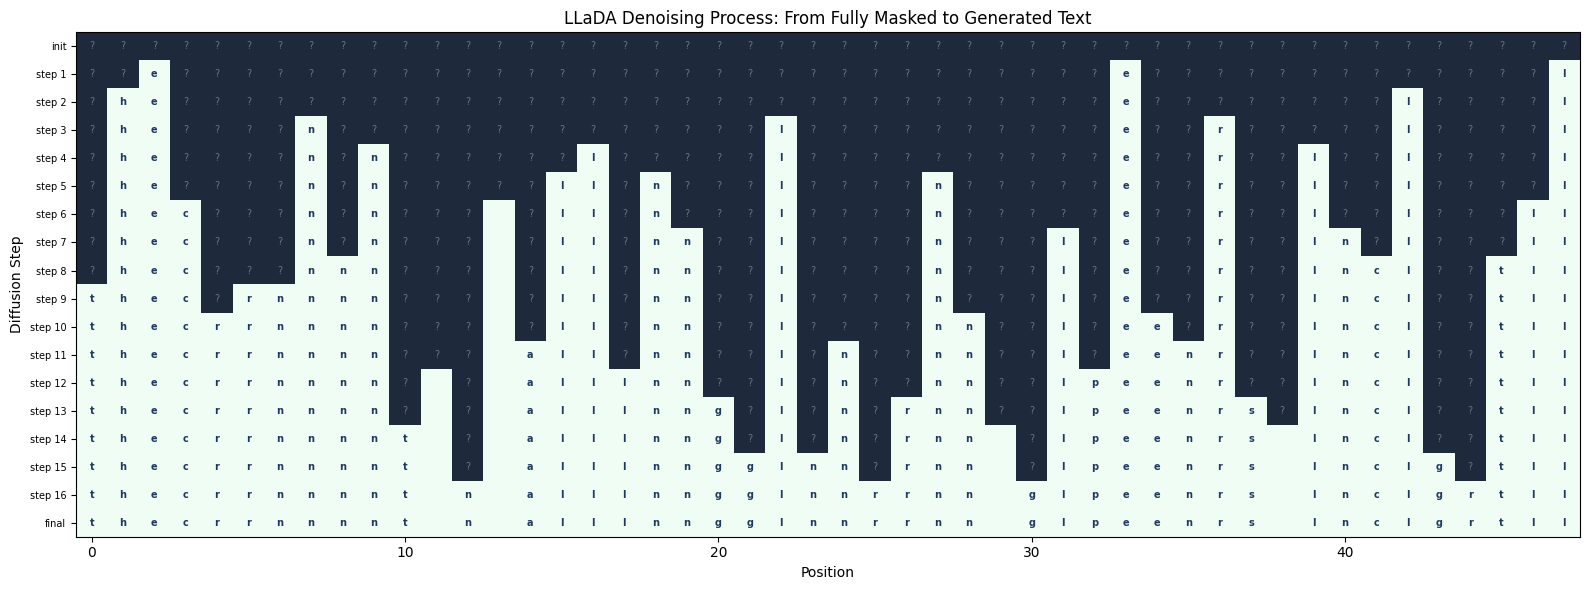

In [10]:
result, hist = sample_with_history(model, SEQ_LEN, DIFFUSION_STEPS, greedy=True)

fig, ax = plt.subplots(figsize=(16, 6))
n_steps = len(hist)
n_cols = SEQ_LEN

grid = np.zeros((n_steps, n_cols))
for i, state in enumerate(hist):
    for j in range(min(len(state), n_cols)):
        ch = state[j]
        if ch == 'M':  # mask
            grid[i, j] = 0
        else:
            grid[i, j] = 1

cmap = plt.cm.colors.ListedColormap(['#1e293b', '#f0fdf4'])
ax.imshow(grid, cmap=cmap, aspect='auto', interpolation='nearest')

for i, state in enumerate(hist):
    for j in range(min(len(state), n_cols)):
        ch = state[j]
        if ch == 'M':
            ax.text(j, i, '?', ha='center', va='center', fontsize=7, color='#64748b')
        elif ch.strip():
            ax.text(j, i, ch, ha='center', va='center', fontsize=7, color='#1e3a5f', fontweight='bold')

ax.set_xlabel('Position')
ax.set_ylabel('Diffusion Step')
ax.set_title('LLaDA Denoising Process: From Fully Masked to Generated Text')
ax.set_yticks(range(n_steps))
ax.set_yticklabels(['init'] + [f'step {i}' for i in range(1, n_steps - 1)] + ['final'], fontsize=7)
plt.tight_layout()
plt.show()

## 10. Evaluation

We evaluate the model's token prediction accuracy on masked positions at various
masking ratios, measuring how well the bidirectional model can infer tokens
from context on both sides.

In [11]:
def evaluate_accuracy(model, data, t_fixed=0.5, n_trials=20):
    """Evaluate token prediction accuracy at a fixed masking ratio t."""
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for trial in range(n_trials):
            for batch in get_batch(data, BATCH_SIZE, seed_offset=trial * 1000):
                batch = batch.to(DEVICE)
                x_masked, mask = forward_mask(batch, t_fixed)
                logits = model(x_masked)
                preds = logits.argmax(dim=-1)
                mask_flat = mask.reshape(-1)
                correct += (preds.reshape(-1)[mask_flat] == batch.reshape(-1)[mask_flat]).sum().item()
                total += mask_flat.sum().item()
    return correct / max(total, 1)

ratios = [0.1, 0.25, 0.5, 0.75, 0.9]
accuracies = []
for t in ratios:
    acc = evaluate_accuracy(model, data, t_fixed=t, n_trials=10)
    accuracies.append(acc)
    print(f'Masking ratio t={t:.2f}: token accuracy = {acc:.4f}')

random_acc = 1.0 / VOCAB_SIZE
print(f'Baseline (random): {random_acc:.4f}')

Masking ratio t=0.10: token accuracy = 0.1577
Masking ratio t=0.25: token accuracy = 0.1608
Masking ratio t=0.50: token accuracy = 0.1587


Masking ratio t=0.75: token accuracy = 0.1603
Masking ratio t=0.90: token accuracy = 0.1606
Baseline (random): 0.0345


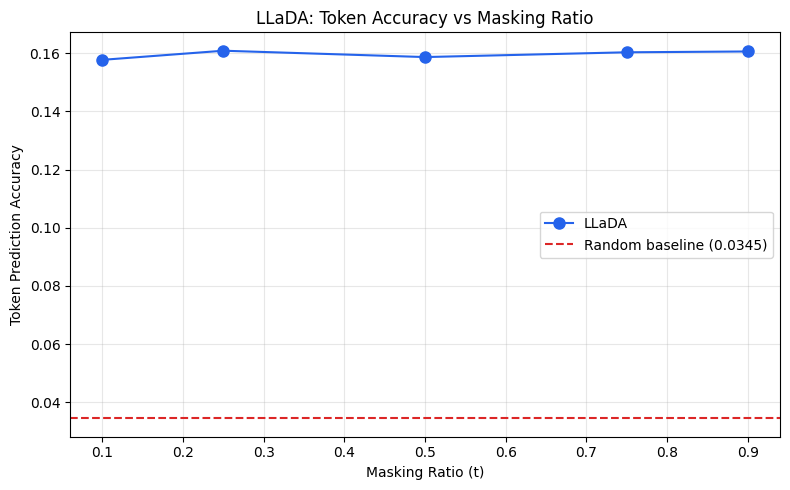

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(ratios, accuracies, 'o-', color='#2563eb', markersize=8, label='LLaDA')
plt.axhline(y=random_acc, color='#dc2626', linestyle='--', label=f'Random baseline ({random_acc:.4f})')
plt.xlabel('Masking Ratio (t)')
plt.ylabel('Token Prediction Accuracy')
plt.title('LLaDA: Token Accuracy vs Masking Ratio')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

### What we built
- A bidirectional Transformer (4 layers, d_model=128, ~803K parameters) trained with LLaDA's masked diffusion objective
- Forward process: random masking with t ~ U(0,1); training loss: CE on masked tokens weighted by 1/t (Eq. 3)
- Reverse process: iterative denoising with low-confidence remasking over 16 diffusion steps
- Trained for **30 epochs** with AdamW (lr=1e-3, wd=0.1)

### What the run above shows
- **Training convergence:** diffusion loss decreases from ~65 to ~6 over 30 epochs (with high variance due to the tiny dataset), showing the model learns to predict masked tokens from bidirectional context.
- **Denoising visualization:** the step-by-step output shows tokens being filled in from a fully masked sequence, with high-confidence tokens appearing first — the core visual signature of LLaDA's diffusion process.
- **Masking ratio analysis:** token prediction accuracy is about 0.16 at all masking ratios (vs a random baseline of 0.0345), roughly flat across t values because the tiny model has not learned enough to benefit strongly from additional context.
- At toy scale the generated text is not coherent — the model produces character-like patterns but cannot form words or sentences with only 129 training examples. This is not comparable to the paper's 8B model trained on 2.3T tokens.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The paper's LLaDA 8B was trained on 2.3 trillion tokens with 0.13M H800 GPU hours.
Our toy model trains on 129 sentences for 30 epochs on a single GPU in under a minute.
The purpose is to demonstrate the masked diffusion training and denoising mechanism,
not to achieve competitive language modeling performance.

### Paper reference
Nie, S., Zhu, F., You, Z., Zhang, X., Ou, J., Hu, J., Zhou, J., Lin, Y., Wen, J.-R., & Li, C. (2025).
*Large Language Diffusion Models.* arXiv:2502.09992.